# SparseCodec training curves

Plots every loss and metric written to `train_log.txt`, for train and valid (and test where available).

`train_log.txt` contains three kinds of lines, which are parsed separately:

| line | written | contains |
|---|---|---|
| **epoch** | once per epoch | `train ...` (epoch mean) and `valid ...` metrics, `lr`, `steps` |
| **step** | every `loss_log_interval` optimizer steps | mean of the raw (unweighted) `train ...` loss terms over the last N steps |
| **test** | once at the end | `test ...` metrics (`Epoch loaded: N`) |

All plots use the **optimizer step** as x-axis, so the thin step-level curves and the epoch-level markers line up.
Ticks and dotted lines mark the **end of each epoch**; the yellow band is the sparse-only warmup (no ASR/speaker losses).
If a run was interrupted and resumed from a checkpoint, the log contains the replayed steps twice; only the latest attempt is plotted.

Edit the settings in the next cell, then run all cells.

In [1]:
import math
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------- settings -------------------------------
LOG_PATH = '/storage/anakuzne/debug_claude/train_log.txt'
START_EPOCH = 1            # first epoch to show (e.g. 2 hides the warmup epoch)
SMOOTH_WINDOW = 5          # rolling mean over the step-level rows (1 = no smoothing)
DROP_SUPERSEDED = True     # a resumed/restarted run rewrites the log from its checkpoint step: drop the older rows it replaces
SAVE_FIGS = False          # also write every figure as a PNG into SAVE_DIR
SAVE_DIR = '.'
HPARAMS_PATH = os.path.join(os.path.dirname(LOG_PATH), 'hyperparams.yaml')  # used for loss weights
WEIGHT_OVERRIDES = {}      # e.g. {'ctc_weight': 8000.0} if hyperparams.yaml is not available

EXPERIMENT_NAME = os.path.basename(os.path.dirname(LOG_PATH))
TRAIN_COLOR, VALID_COLOR, TEST_COLOR = 'royalblue', 'darkorange', 'crimson'

In [2]:
def parse_log(path, drop_superseded=True):
    """Parse a SpeechBrain train_log.txt into one DataFrame.

    Every line is split into ' - ' separated sections and each section into
    comma-separated 'key: value' pairs. Lines are classified as:
      'step'  : periodic loss line (has 'avg_over_last')
      'test'  : final test line ('Epoch loaded' is renamed to 'epoch')
      'epoch' : per-epoch train/valid summary (has 'lr')

    The file is only ever appended to. When training is interrupted and resumed
    from a checkpoint (or restarted), the optimizer step counter goes back and
    the same steps are logged again. With drop_superseded=True the older rows at
    or after the restart step are discarded, so every step appears once and the
    latest attempt wins. Rows before the restart point are kept.
    Returns (DataFrame, number of dropped rows).
    """
    rows, dropped = [], 0
    with open(path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            row = {}
            for section in line.split(' - '):
                for item in section.split(','):
                    if ':' not in item:
                        continue
                    key, value = item.split(':', 1)
                    row[key.strip()] = value.strip()
            if 'avg_over_last' in row:
                row['kind'] = 'step'
            elif 'Epoch loaded' in row:
                row['kind'] = 'test'
                row['epoch'] = row.pop('Epoch loaded')
            elif 'lr' in row:
                row['kind'] = 'epoch'
            else:
                continue

            if drop_superseded and row['kind'] != 'test':
                steps = float(row['steps'])
                cut = len(rows)
                for j in range(len(rows) - 1, -1, -1):
                    if rows[j]['kind'] == 'test':
                        continue
                    if float(rows[j]['steps']) >= steps:
                        cut = j
                    else:
                        break
                dropped += len(rows) - cut
                del rows[cut:]
            rows.append(row)

    df = pd.DataFrame(rows)
    for col in df.columns:
        if col not in ('kind', 'optimizer'):
            df[col] = pd.to_numeric(df[col], errors='coerce')
    return df, dropped


raw, n_dropped = parse_log(LOG_PATH, DROP_SUPERSEDED)


def select(kind):
    """Rows of one kind at or after START_EPOCH, without all-empty columns."""
    sel = raw[(raw['kind'] == kind) & (raw['epoch'] >= START_EPOCH)]
    return sel.dropna(axis=1, how='all').reset_index(drop=True)


epoch_df, step_df, test_df = select('epoch'), select('step'), select('test')
LOG_INTERVAL = int(step_df['avg_over_last'].median()) if 'avg_over_last' in step_df else None

# Warmup epochs: step lines exist but never contain the ASR (CTC) loss.
warmup_epochs = []
if len(step_df):
    with_ctc = set(step_df.loc[step_df['train ctc_loss'].notna(), 'epoch']) if 'train ctc_loss' in step_df else set()
    warmup_epochs = sorted(set(step_df['epoch']) - with_ctc)
warmup_end_step = epoch_df.loc[epoch_df['epoch'].isin(warmup_epochs), 'steps'].max() if warmup_epochs else None

print('log          :', LOG_PATH)
print('superseded   : %d older rows dropped (resumed/restarted run rewrote those steps)' % n_dropped)
print('epoch rows   : %d | step rows: %d (every %s steps) | test rows: %d' % (len(epoch_df), len(step_df), LOG_INTERVAL, len(test_df)))
print('warmup epochs:', warmup_epochs or 'none')

log          : /storage/anakuzne/debug_claude/train_log.txt
superseded   : 4 older rows dropped (resumed/restarted run rewrote those steps)
epoch rows   : 20 | step rows: 295 (every 100 steps) | test rows: 1
warmup epochs: [1]


In [3]:
COVERED = set()  # metrics drawn by the cells below; the last plotting cell shows the rest


def epoch_end_step(epoch):
    """Optimizer step at the end of an epoch (x position of epoch-level values)."""
    match = epoch_df.loc[epoch_df['epoch'] == epoch, 'steps']
    return match.iloc[0] if len(match) else epoch_df['steps'].max()


def decorate(ax, title, ylabel, log=False):
    """Epoch ticks, warmup band, grid, legend."""
    ticks = epoch_df['steps'].values
    labels = epoch_df['epoch'].astype(int).values
    stride = max(1, int(math.ceil(len(ticks) / 20.0)))
    ax.set_xticks(ticks[::stride])
    ax.set_xticklabels(labels[::stride])
    for tick in ticks:
        ax.axvline(tick, color='gray', lw=0.5, ls=':', alpha=0.4)
    if warmup_end_step is not None:
        ax.axvspan(0, warmup_end_step, color='gold', alpha=0.12, lw=0)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel(ylabel)
    ax.set_xlabel('Epoch (tick = end of epoch)')
    ax.grid(True, which='both', ls='-', alpha=0.2)
    handles, names = ax.get_legend_handles_labels()
    if handles:
        ax.legend(fontsize=8)


def plot_metric(ax, metric, title=None, ylabel=None, log=False, scale=1.0,
                train=True, valid=True, test=False, hline=None, hline_label=None):
    """Draw 'train <metric>' / 'valid <metric>' / 'test <metric>' on one axis.

    train: thin step-level curve (if logged every N steps) + epoch-mean markers.
    valid: epoch-level markers.   test: star markers at the loaded epoch.
    scale: multiplier applied to the values (100 turns a fraction into %).
    """
    COVERED.add(metric)
    lowest = np.inf
    col_train, col_valid, col_test = 'train ' + metric, 'valid ' + metric, 'test ' + metric

    if train and col_train in step_df.columns:
        s = step_df[['steps', col_train]].dropna()
        y = s[col_train].rolling(SMOOTH_WINDOW, min_periods=1).mean() * scale
        ax.plot(s['steps'], y, color=TRAIN_COLOR, alpha=0.45, lw=1.2, label='train (every %s steps)' % LOG_INTERVAL)
        lowest = min(lowest, y.min())
    if train and col_train in epoch_df.columns:
        s = epoch_df[['steps', col_train]].dropna()
        if len(s):
            ax.plot(s['steps'], s[col_train] * scale, '-o', color=TRAIN_COLOR, ms=4, lw=2, label='train (epoch mean)')
            lowest = min(lowest, (s[col_train] * scale).min())
    if valid and col_valid in epoch_df.columns:
        s = epoch_df[['steps', col_valid]].dropna()
        if len(s):
            ax.plot(s['steps'], s[col_valid] * scale, '--s', color=VALID_COLOR, ms=5, lw=2, label='valid', zorder=5)
            lowest = min(lowest, (s[col_valid] * scale).min())
    if test and col_test in test_df.columns:
        # ax.plot (not scatter) so that the y-axis autoscaling includes the test point
        for k, (_, row) in enumerate(test_df[['epoch', col_test]].dropna().iterrows()):
            ax.plot([epoch_end_step(row['epoch'])], [row[col_test] * scale], ls='', marker='*', ms=15,
                    color=TEST_COLOR, markeredgecolor='black', zorder=6, label='test' if k == 0 else None)
            lowest = min(lowest, row[col_test] * scale)
    if hline is not None:
        ax.axhline(hline, color='gray', ls='--', lw=1, label=hline_label)
    if log and lowest > 0:
        ax.set_yscale('log')
    decorate(ax, title or metric, ylabel or metric, log)


def has_metric(metric):
    """True if any train/valid/test column of this metric has data."""
    for frame in (step_df, epoch_df, test_df):
        for prefix in ('train ', 'valid ', 'test '):
            if prefix + metric in frame.columns:
                return True
    return False


def finish(fig, name, top=0.93):
    fig.tight_layout(rect=[0, 0, 1, top])
    if SAVE_FIGS:
        fig.savefig(os.path.join(SAVE_DIR, name + '.png'), dpi=150, bbox_inches='tight')
    plt.show()


def plot_grid(specs, title, name, ncols=3, cell_size=(5.6, 3.8)):
    """One subplot per spec dict (keyword arguments of plot_metric); missing metrics are skipped."""
    specs = [s for s in specs if has_metric(s['metric'])]
    if not specs:
        print('Nothing to plot for:', title)
        return
    nrows = int(math.ceil(len(specs) / float(ncols)))
    ncols = min(ncols, len(specs))
    fig, axes = plt.subplots(nrows, ncols, figsize=(cell_size[0] * ncols, cell_size[1] * nrows), squeeze=False)
    for ax, spec in zip(axes.ravel(), specs):
        plot_metric(ax, **spec)
    for ax in axes.ravel()[len(specs):]:
        ax.axis('off')
    fig.suptitle('%s - %s (epoch %d+)' % (title, EXPERIMENT_NAME, START_EPOCH), fontsize=13)
    finish(fig, name)

## 1. Total loss: train vs valid (+ test)

Train is the epoch mean of the optimised (weighted) total loss. Valid uses the same weighted sum on the dev set.
The **test loss is not comparable** with them: in the test stage the recipe only computes the CTC loss and the
regularizers (no reconstruction or AAM term), so it is much lower.

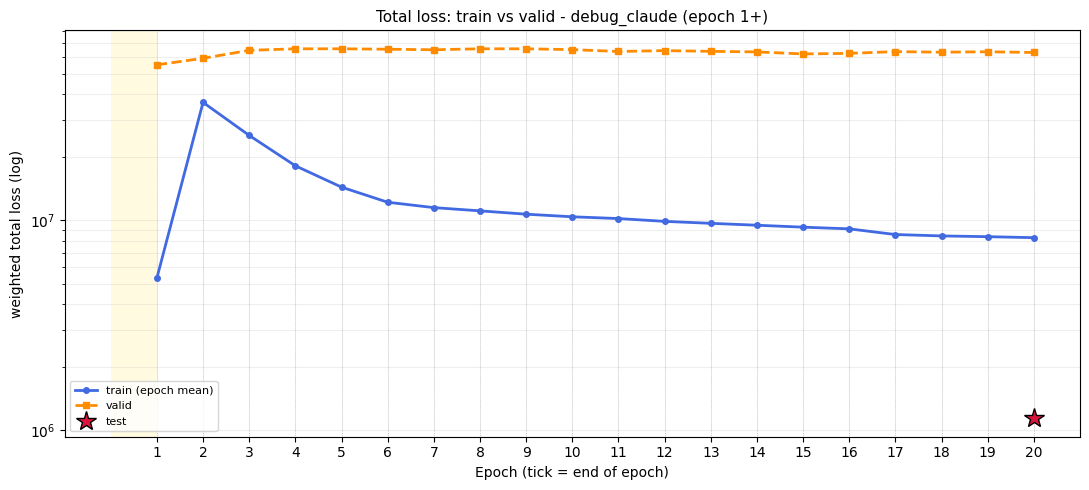

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
plot_metric(ax, 'loss', title='Total loss: train vs valid - %s (epoch %d+)' % (EXPERIMENT_NAME, START_EPOCH),
            ylabel='weighted total loss (log)', log=True, test=True)
finish(fig, 'total_loss', top=1.0)

## 2. Individual training loss terms

Raw (**unweighted**) terms, averaged over every `loss_log_interval` steps. Only train is logged at this granularity.
`recon_loss` is a sum over feature dimensions and frames, which is why its scale is so large.

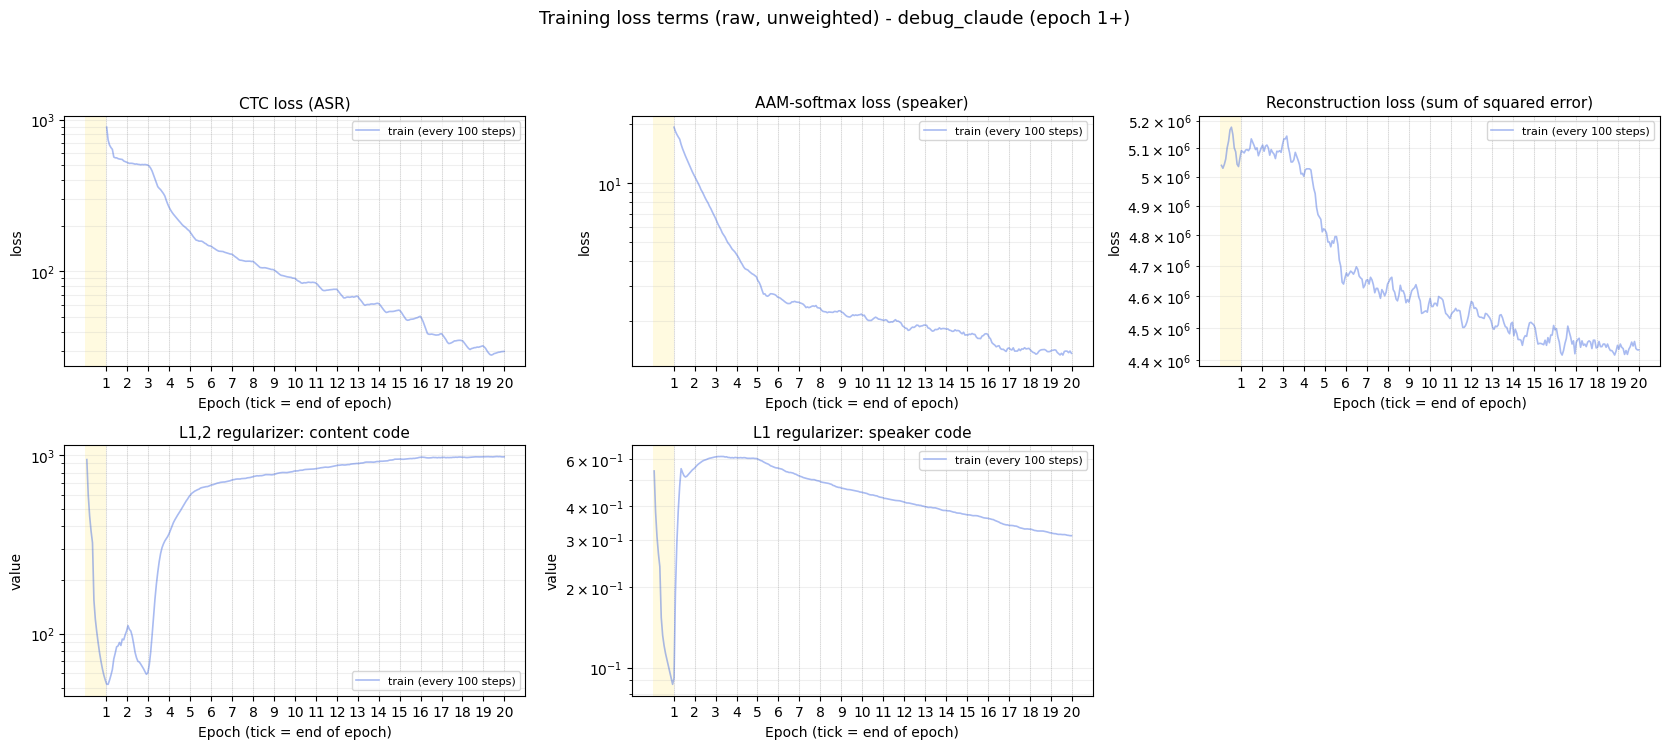

In [5]:
plot_grid([
    dict(metric='ctc_loss', title='CTC loss (ASR)', ylabel='loss', log=True, valid=False),
    dict(metric='aam_loss', title='AAM-softmax loss (speaker)', ylabel='loss', log=True, valid=False),
    dict(metric='recon_loss', title='Reconstruction loss (sum of squared error)', ylabel='loss', log=True, valid=False),
    dict(metric='total_l12_reg_content', title='L1,2 regularizer: content code', ylabel='value', log=True, valid=False),
    dict(metric='total_l1_reg_speaker', title='L1 regularizer: speaker code', ylabel='value', log=True, valid=False),
], 'Training loss terms (raw, unweighted)', 'train_loss_terms')

## 3. How much does each term contribute to the optimised loss?

Each raw term multiplied by its weight from `hyperparams.yaml`. A term whose share is well below 1% has almost no influence on training,
whatever its raw value. The black dashed line (sum of weighted terms) should match the logged train loss.

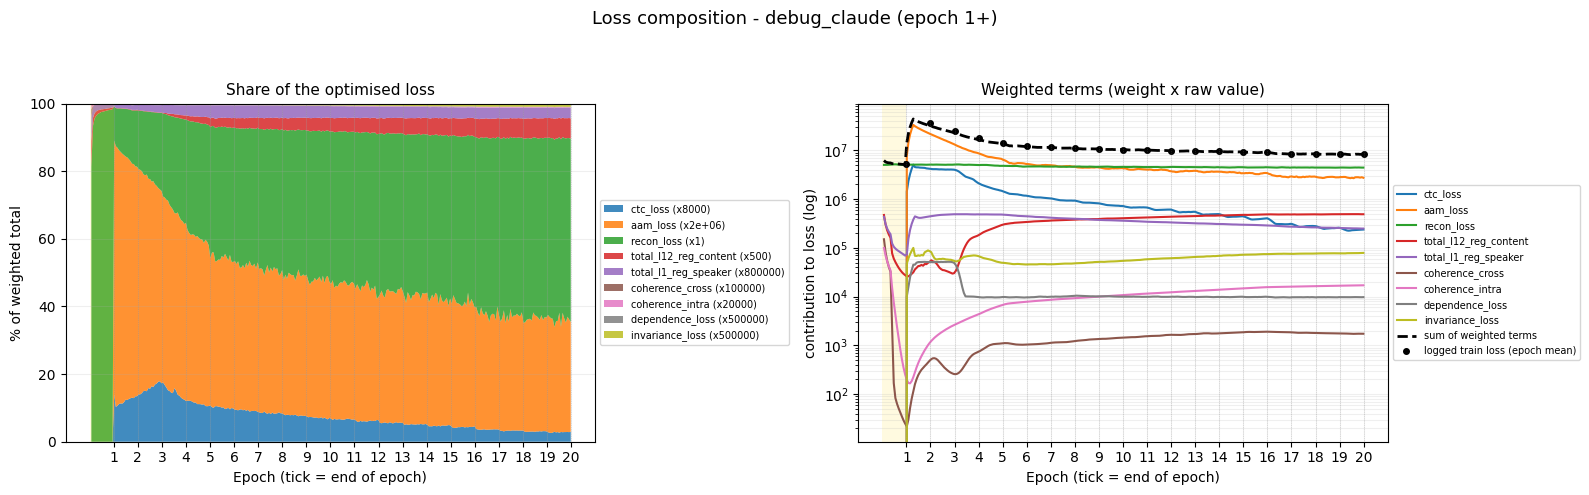

Share of the weighted loss at the last logged step (29500):
recon_loss               54.20
aam_loss                 32.47
total_l12_reg_content     5.99
total_l1_reg_speaker      3.06
ctc_loss                  2.97
invariance_loss           0.96
coherence_intra           0.21
dependence_loss           0.12
coherence_cross           0.02


In [6]:
LOSS_TERMS = [  # (logged metric, hyperparameter holding its weight, weight if the hyperparameter is absent)
    ('ctc_loss', 'ctc_weight', 1.0),
    ('aam_loss', 'spk_aam_loss_weight', 1.0),
    ('recon_loss', 'sparse_loss_weight', 1.0),
    ('total_l12_reg_content', 'content_reg_weight', 1.0),
    ('total_l1_reg_speaker', 'spk_reg_weight', 1.0),
    ('coherence_cross', 'coherence_weight', 0.0),
    ('coherence_intra', 'intra_coherence_weight', 0.0),
    ('dependence_loss', 'dependence_weight', 0.0),
    ('invariance_loss', 'invariance_weight', 0.0),
]


def load_numeric_hparams(path):
    """Top-level numeric entries of hyperparams.yaml (custom !tags are ignored)."""
    try:
        import yaml
    except ImportError:
        return {}

    class Loader(yaml.SafeLoader):
        pass

    Loader.add_multi_constructor('!', lambda loader, suffix, node: None)
    Loader.add_multi_constructor('tag:', lambda loader, suffix, node: None)
    try:
        with open(path) as f:
            hparams = yaml.load(f, Loader=Loader) or {}
    except (OSError, yaml.YAMLError):
        return {}
    numeric = {}
    for key, value in hparams.items():
        try:
            numeric[key] = float(value)  # also parses strings such as '2.0e6'
        except (TypeError, ValueError):
            pass
    return numeric


weights = load_numeric_hparams(HPARAMS_PATH)
weights.update(WEIGHT_OVERRIDES)

terms = []
for metric, hparam, default in LOSS_TERMS:
    weight = weights.get(hparam, default if weights else None)
    if weight and ('train ' + metric) in step_df.columns:
        terms.append((metric, weight))

if not len(step_df) or not terms or not weights:
    print('Skipped: needs step-level rows and loss weights (%s not found; use WEIGHT_OVERRIDES).' % HPARAMS_PATH)
else:
    weighted = pd.DataFrame({m: step_df['train ' + m].fillna(0.0) * w for m, w in terms})
    weighted.index = step_df['steps'].values
    total = weighted.sum(axis=1)
    share = 100.0 * weighted.div(total, axis=0)

    fig, (ax_share, ax_abs) = plt.subplots(1, 2, figsize=(16, 5))
    ax_share.stackplot(share.index, share.T.values, labels=['%s (x%g)' % (m, w) for m, w in terms], alpha=0.85)
    ax_share.set_ylim(0, 100)
    decorate(ax_share, 'Share of the optimised loss', '% of weighted total')
    ax_share.legend(fontsize=7, loc='center left', bbox_to_anchor=(1.0, 0.5))

    for metric, weight in terms:
        ax_abs.plot(weighted.index, weighted[metric].rolling(SMOOTH_WINDOW, min_periods=1).mean(), lw=1.5, label=metric)
    ax_abs.plot(total.index, total.rolling(SMOOTH_WINDOW, min_periods=1).mean(), 'k--', lw=2, label='sum of weighted terms')
    if 'train loss' in epoch_df.columns:
        s = epoch_df[['steps', 'train loss']].dropna()
        ax_abs.plot(s['steps'], s['train loss'], 'ko', ms=4, label='logged train loss (epoch mean)')
    ax_abs.set_yscale('log')
    decorate(ax_abs, 'Weighted terms (weight x raw value)', 'contribution to loss (log)')
    ax_abs.legend(fontsize=7, loc='center left', bbox_to_anchor=(1.0, 0.5))
    fig.suptitle('Loss composition - %s (epoch %d+)' % (EXPERIMENT_NAME, START_EPOCH), fontsize=13)
    finish(fig, 'loss_composition')

    last = share.iloc[-1].sort_values(ascending=False)
    print('Share of the weighted loss at the last logged step (%d):' % share.index[-1])
    print(last.round(2).to_string())
    COVERED.update(m for m, _ in terms)

## 4. Speaker-leakage regularizers

* `coherence_cross`: overlap between content and speaker dictionary atoms (0 = orthogonal subspaces).
* `coherence_intra`: redundancy among atoms of the same branch.
* `dependence_loss`: correlation between pooled content statistics and the speaker code (noise floor about 1/(batch-1)).
* `invariance_loss`: change of the content code under a pitch shift (train only).

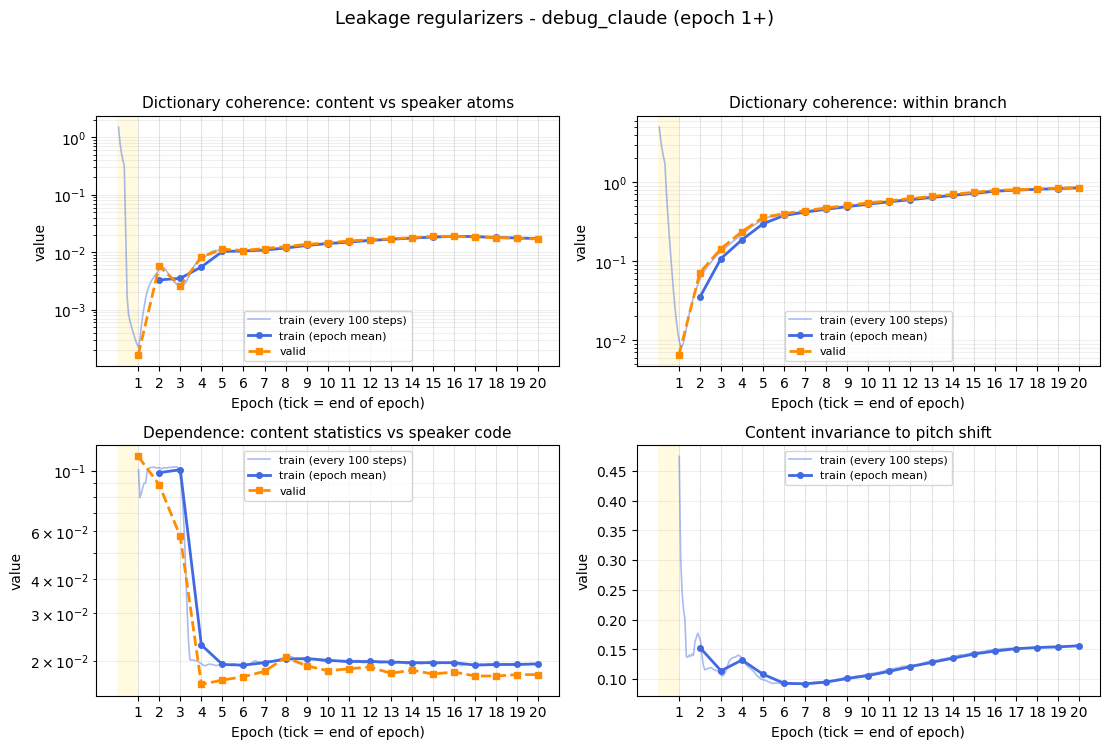

In [7]:
plot_grid([
    dict(metric='coherence_cross', title='Dictionary coherence: content vs speaker atoms', ylabel='value', log=True),
    dict(metric='coherence_intra', title='Dictionary coherence: within branch', ylabel='value', log=True),
    dict(metric='dependence_loss', title='Dependence: content statistics vs speaker code', ylabel='value', log=True),
    dict(metric='invariance_loss', title='Content invariance to pitch shift', ylabel='value', log=False),
], 'Leakage regularizers', 'leakage_regularizers', ncols=2)

## 5. Sparsity and active density per layer

`sparsity` is the percentage of (near-)zero code entries; `active_density_layer_k` the percentage of non-zero entries in layer *k*.

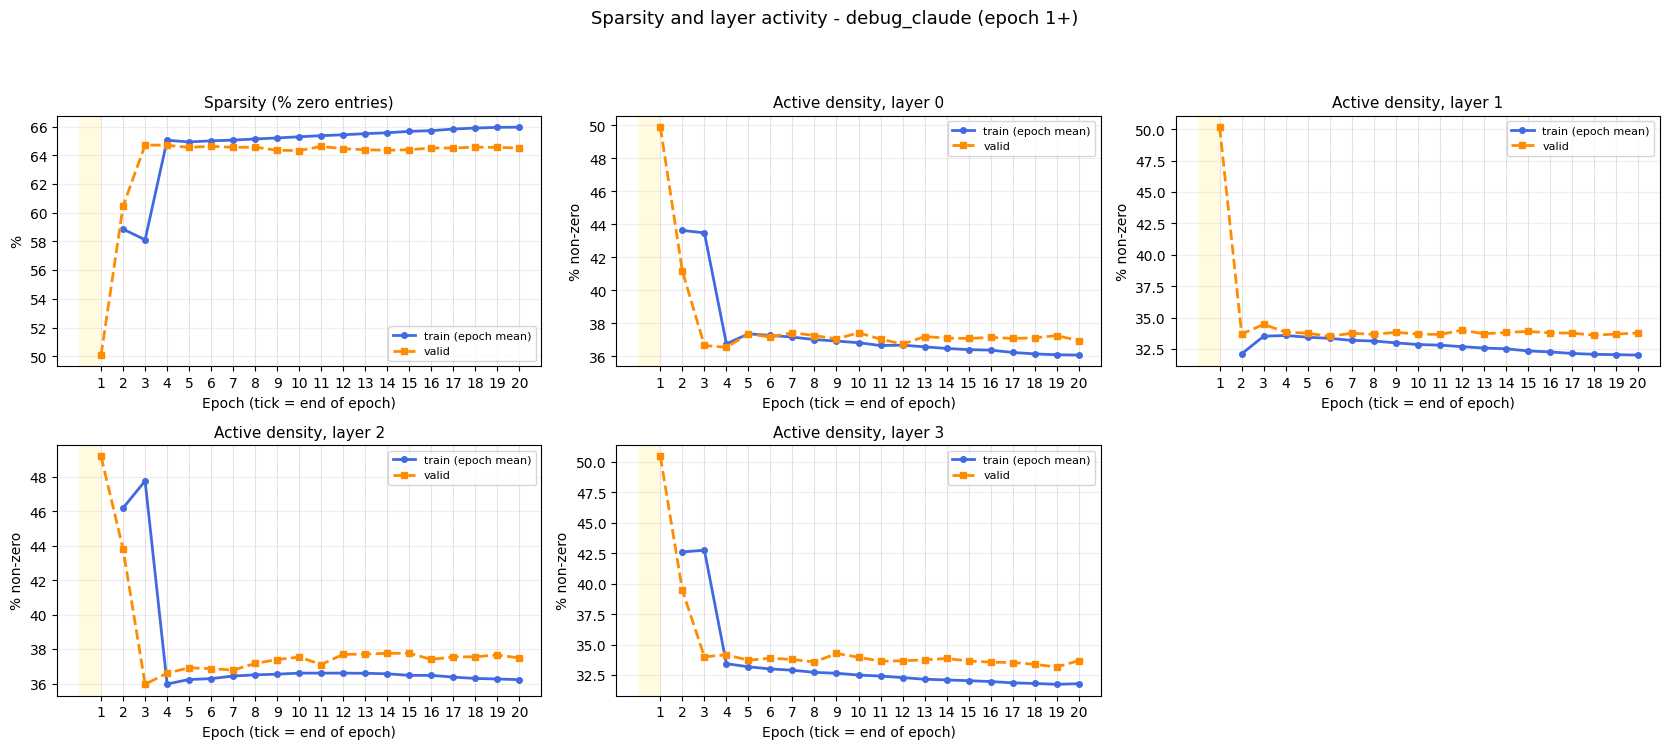

In [8]:
layer_ids = sorted({int(c.rsplit('_', 1)[1]) for frame in (epoch_df, step_df)
                    for c in frame.columns if c.startswith(('train active_density_layer_', 'valid active_density_layer_'))})
plot_grid(
    [dict(metric='sparsity', title='Sparsity (% zero entries)', ylabel='%')]
    + [dict(metric='active_density_layer_%d' % i, title='Active density, layer %d' % i, ylabel='% non-zero')
       for i in layer_ids],
    'Sparsity and layer activity', 'sparsity_density')

## 6. Quality metrics (valid curve, test = star)

* `WER` in %.
* `EER`: speaker verification with the **speaker** code.
* `leak_EER`: the same verification on the pooled **content** code. About 50% means no speaker information can be read from it; lower means more leakage.
* `ErrorRate`: speaker classification error.

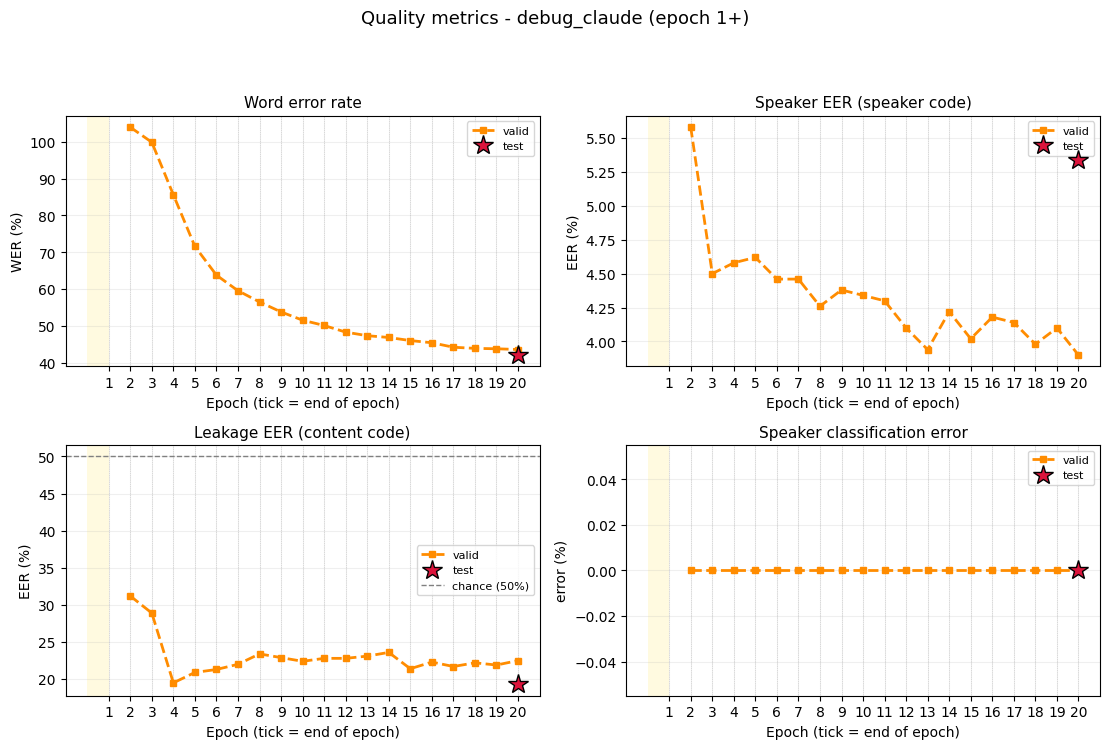

In [9]:
plot_grid([
    dict(metric='WER', title='Word error rate', ylabel='WER (%)', train=False, test=True),
    dict(metric='EER', title='Speaker EER (speaker code)', ylabel='EER (%)', scale=100, train=False, test=True),
    dict(metric='leak_EER', title='Leakage EER (content code)', ylabel='EER (%)', scale=100, train=False, test=True,
         hline=50, hline_label='chance (50%)'),
    dict(metric='ErrorRate', title='Speaker classification error', ylabel='error (%)', scale=100, train=False, test=True),
], 'Quality metrics', 'quality_metrics', ncols=2)

# Sanity check: a metric that is exactly 0 (or NaN) at every epoch is almost certainly not being computed correctly.
for metric in ('WER', 'EER', 'leak_EER', 'ErrorRate'):
    col = 'valid ' + metric
    if col in epoch_df.columns:
        values = epoch_df[col].dropna()
        if len(values) > 1 and (values == 0).all():
            print('WARNING: %s is exactly 0 at every epoch. Check how this metric is computed before trusting it.' % col)

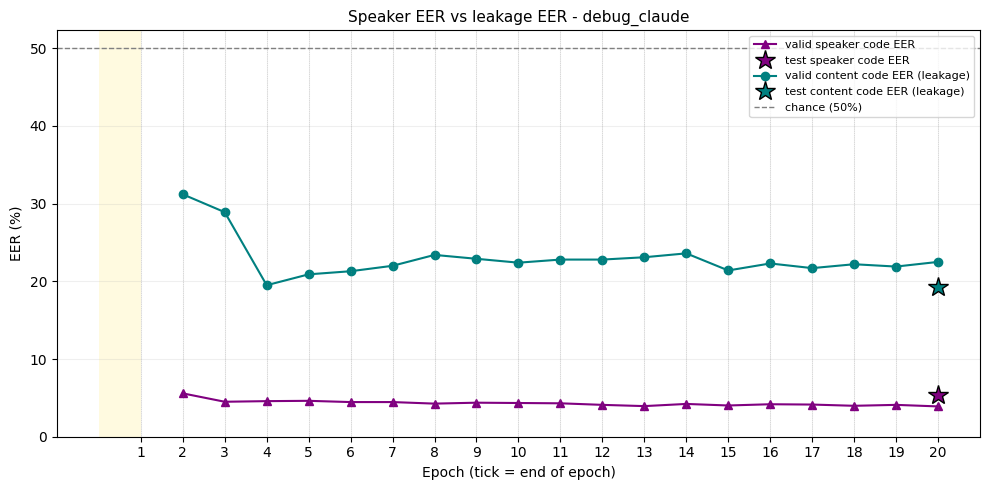

In [10]:
# Speaker code vs content code on the same axes: the gap is how much more speaker
# identity the speaker branch carries than the content branch.
if has_metric('EER') and has_metric('leak_EER'):
    fig, ax = plt.subplots(figsize=(10, 5))
    for metric, label, color, marker in [('EER', 'speaker code EER', 'purple', '^'), ('leak_EER', 'content code EER (leakage)', 'teal', 'o')]:
        s = epoch_df[['steps', 'valid ' + metric]].dropna()
        ax.plot(s['steps'], 100 * s['valid ' + metric], '-' + marker, color=color, label='valid ' + label)
        if 'test ' + metric in test_df.columns:
            for k, (_, row) in enumerate(test_df[['epoch', 'test ' + metric]].dropna().iterrows()):
                ax.plot([epoch_end_step(row['epoch'])], [100 * row['test ' + metric]], ls='', marker='*', ms=15,
                        color=color, markeredgecolor='black', zorder=6, label='test ' + label if k == 0 else None)
    ax.axhline(50, color='gray', ls='--', lw=1, label='chance (50%)')
    ax.set_ylim(bottom=0)
    decorate(ax, 'Speaker EER vs leakage EER - %s' % EXPERIMENT_NAME, 'EER (%)')
    finish(fig, 'eer_vs_leak_eer', top=1.0)

## 7. Learning rate

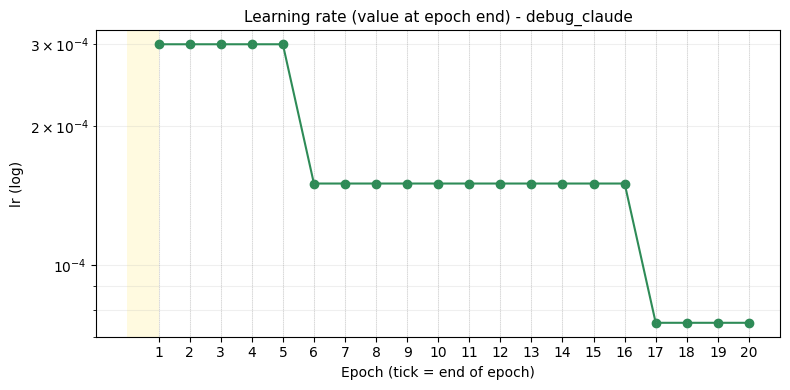

In [11]:
if 'lr' in epoch_df.columns:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(epoch_df['steps'], epoch_df['lr'], '-o', color='seagreen')
    ax.set_yscale('log')
    decorate(ax, 'Learning rate (value at epoch end) - %s' % EXPERIMENT_NAME, 'lr (log)')
    finish(fig, 'learning_rate', top=1.0)

## 8. Any other logged metrics

Anything in the log that the cells above did not draw (e.g. metrics added later) is plotted here automatically.

In [12]:
def metric_names(frame):
    names = set()
    for col in frame.columns:
        prefix, _, name = col.partition(' ')
        if prefix in ('train', 'valid', 'test') and name:
            names.add(name)
    return names


extras = sorted((metric_names(epoch_df) | metric_names(step_df) | metric_names(test_df)) - COVERED)
if extras:
    plot_grid([dict(metric=m, title=m, ylabel=m, test=True) for m in extras], 'Other logged metrics', 'other_metrics')
else:
    print('All logged metrics are already plotted above.')

All logged metrics are already plotted above.


## 9. Summary table

In [13]:
summary = {}
if len(epoch_df):
    last_row = epoch_df.iloc[-1]
    for col in epoch_df.columns:
        prefix, _, name = col.partition(' ')
        if prefix in ('train', 'valid') and pd.notna(last_row[col]):
            summary.setdefault(name, {})['last epoch %s' % prefix] = last_row[col]
if len(test_df):
    for col in test_df.columns:
        prefix, _, name = col.partition(' ')
        if prefix == 'test' and test_df[col].notna().any():
            summary.setdefault(name, {})['test'] = test_df[col].dropna().iloc[-1]
table = pd.DataFrame(summary).T.reindex(columns=['last epoch train', 'last epoch valid', 'test'])
print('Last epoch: %s' % (int(epoch_df['epoch'].iloc[-1]) if len(epoch_df) else 'n/a'))
# DataFrame.map replaced applymap in pandas 2.1
elementwise = getattr(table, 'map', None) or table.applymap
display(elementwise(lambda v: '-' if pd.isna(v) else '%.4g' % v))

if 'valid WER' in epoch_df.columns and epoch_df['valid WER'].notna().any():
    best = epoch_df.loc[epoch_df['valid WER'].idxmin()]
    print('Best valid WER: %.2f at epoch %d (valid EER %.2f%%, valid leak_EER %s)' % (
        best['valid WER'], best['epoch'], 100 * best.get('valid EER', float('nan')),
        '%.2f%%' % (100 * best['valid leak_EER']) if 'valid leak_EER' in best and pd.notna(best['valid leak_EER']) else 'n/a'))

Last epoch: 20


,last epoch train,last epoch valid,test
coherence_cross,0.0173,0.017,-
coherence_intra,0.849,0.856,-
loss,8.27e+06,6.31e+07,1.14e+06
sparsity,65.97,64.52,-
active_density_layer_0,36.07,36.95,-
active_density_layer_1,32.02,33.77,-
active_density_layer_2,36.23,37.49,-
active_density_layer_3,31.8,33.69,-
dependence_loss,0.0195,0.0178,-
invariance_loss,0.156,-,-


Best valid WER: 43.54 at epoch 20 (valid EER 3.90%, valid leak_EER 22.50%)
